# Notebook 06: Controlled Systematic Ablation Studies

## Experimental Scope & Objectives
This notebook presents five controlled ablation investigations across the four experimental tracks, isolating the causal impact of architectural components, feature representation, trainability, and temporal context under identical 5-fold cross-validation splits:

1. **Ablation 1: CNN Backbone Architectures** — Comparing ResNet50 (residual identity shortcuts), DenseNet121 (dense feature concatenation), and EfficientNet-B0 (compound scaling with inverted bottlenecks).
2. **Ablation 2: RNN Directionality** — Comparing unidirectional LSTM with bidirectional BiLSTM under identical spatial patch/slice features.
3. **Ablation 3: Hybrid CNN–RNN Coupling vs. Unimodal CNNs** — Evaluating whether sequential feature aggregation improves performance over static spatial representations (ResNet50 vs ResNet50+LSTM vs ResNet50+BiLSTM; EfficientNet-B0 vs EfficientNet-B0+BiLSTM).
4. **Ablation 4: Backbone Feature Trainability** — Evaluating transfer learning depth under identical folds:
   - `frozen`: Feature extraction only; backbone weights locked, only the classification head trained.
   - `partial`: Top two convolutional blocks fine-tuned; bottom features frozen.
   - `full`: Complete end-to-end backpropagation through all layers.
   - Evaluated on Fundus (EfficientNet-B0) and Individual OCT (DenseNet121).
5. **Ablation 5: OCT Temporal Window Length** — Evaluating the effect of volumetric slice context on OCT sequence classification using ResNet50+BiLSTM:
   - Window lengths: $L=4$, $L=8$ (baseline), and $L=12$ slices per window.
   - Evaluated at both the **window level** and the **patient sequence level** ($N=21$) via out-of-fold probability pooling.
6. **Efficiency & Computational Tradeoffs** — Synthesizing parameter count, GPU training runtime, and classification Macro-F1 across all architectures.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML, Image

PROJECT_ROOT = Path("..").resolve()
ABL_DIR = PROJECT_ROOT / "results" / "ablation_study"
FIG_DIR = ABL_DIR / "figures"
print(f"Loading ablation artifacts from: {ABL_DIR}")


Loading ablation artifacts from: C:\Users\Shuvendu\Desktop\Papilledema_analysis\results\ablation_study


## 1. Ablation 1: CNN Backbone Comparison Across Experimental Tracks

Comparing the three core convolutional backbones (ResNet50, DenseNet121, EfficientNet-B0) across all 4 experimental tracks under identical 5-fold CV splits.


track,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,accuracy_mean,mcc_mean,total_params,train_time_mean_sec
fundus_3class,densenet121,0.961335,0.009649,0.963234,0.968544,0.946525,0,155.12
fundus_3class,efficientnet_b0,0.959179,0.016450,0.963011,0.965602,0.941763,0,113.84
fundus_3class,resnet50,0.953829,0.014680,0.957292,0.961956,0.935506,0,122.27
oct_individual,densenet121,0.962143,0.047931,0.985527,0.976454,0.941803,0,135.81
oct_individual,efficientnet_b0,0.905027,0.074724,0.948519,0.934129,0.855422,0,89.65
oct_individual,resnet50,0.889502,0.070958,0.921198,0.926429,0.834327,0,104.14
oct_severity,densenet121,0.760145,0.164959,0.822146,0.794347,0.676582,0,97.88
oct_severity,resnet50,0.666914,0.205247,0.749169,0.757936,0.595751,0,82.61
oct_severity,efficientnet_b0,0.599784,0.135289,0.716372,0.663951,0.482714,0,72.53


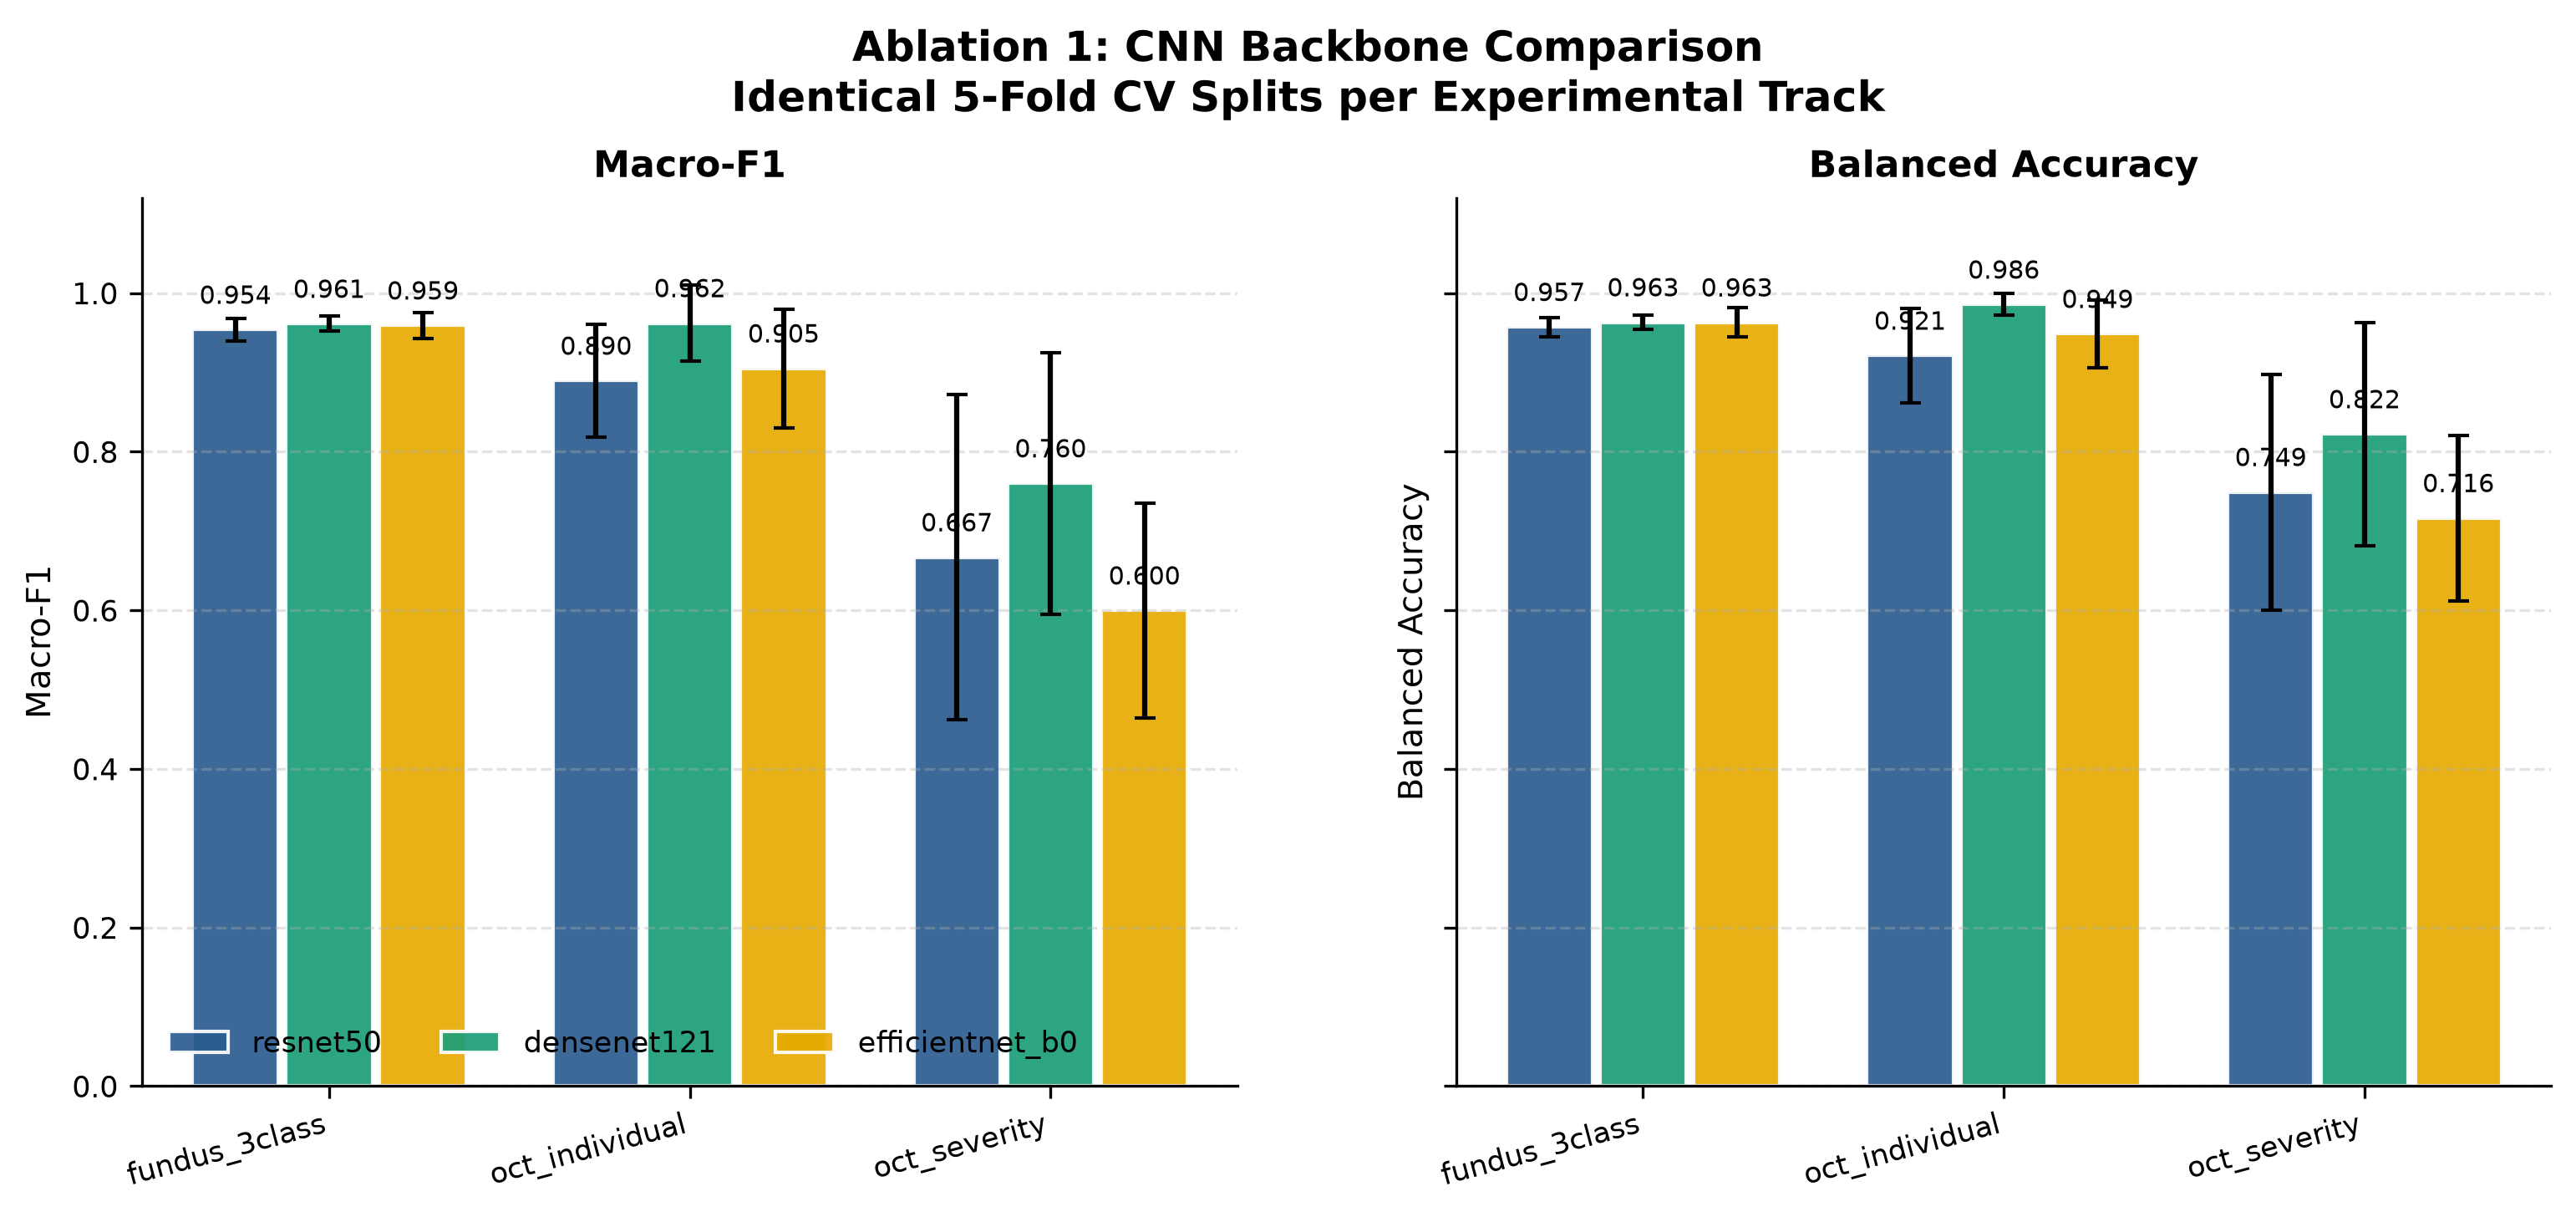

In [2]:
df_abl1 = pd.read_csv(ABL_DIR / "abl01_cnn_backbone_comparison.csv")
display(HTML("<h4>Ablation 1: CNN Backbone Comparison (5-Fold Mean ± SD)</h4>"))
cols_abl = ["track", "model", "macro_f1_mean", "macro_f1_std", "balanced_accuracy_mean", "accuracy_mean", "mcc_mean", "total_params", "train_time_mean_sec"]
display(HTML(df_abl1[cols_abl].to_html(classes="table table-striped table-hover", index=False)))

display(HTML("<h5>Ablation 1 Figure: CNN Backbone Comparison</h5>"))
display(Image(filename=str(FIG_DIR / "abl01_cnn_backbone_comparison.png")))


## 2. Ablation 2: RNN Directionality (Unidirectional LSTM vs. Bidirectional BiLSTM)

Evaluating the benefit of bidirectional context propagation over unidirectional recurrent processing.


track,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,accuracy_mean,mcc_mean,total_params,train_time_mean_sec
fundus_3class,bilstm,0.749979,0.039664,0.761849,0.774739,0.629195,0,234.35
fundus_3class,lstm,0.748293,0.019761,0.762062,0.776129,0.631953,0,146.08
oct_individual,bilstm,0.524531,0.143642,0.597231,0.694310,0.365472,0,198.92
oct_individual,lstm,0.496271,0.151397,0.544637,0.724938,0.323351,0,135.29
oct_sequence,bilstm,0.417525,0.205958,0.464000,0.771188,0.286957,0,56.64
oct_sequence,lstm,0.404657,0.179405,0.425000,0.773100,0.240713,0,48.45
oct_severity,bilstm,0.222168,0.069217,0.262455,0.375953,0.105232,0,103.35
oct_severity,lstm,0.158774,0.060327,0.222055,0.342259,-0.106752,0,68.30


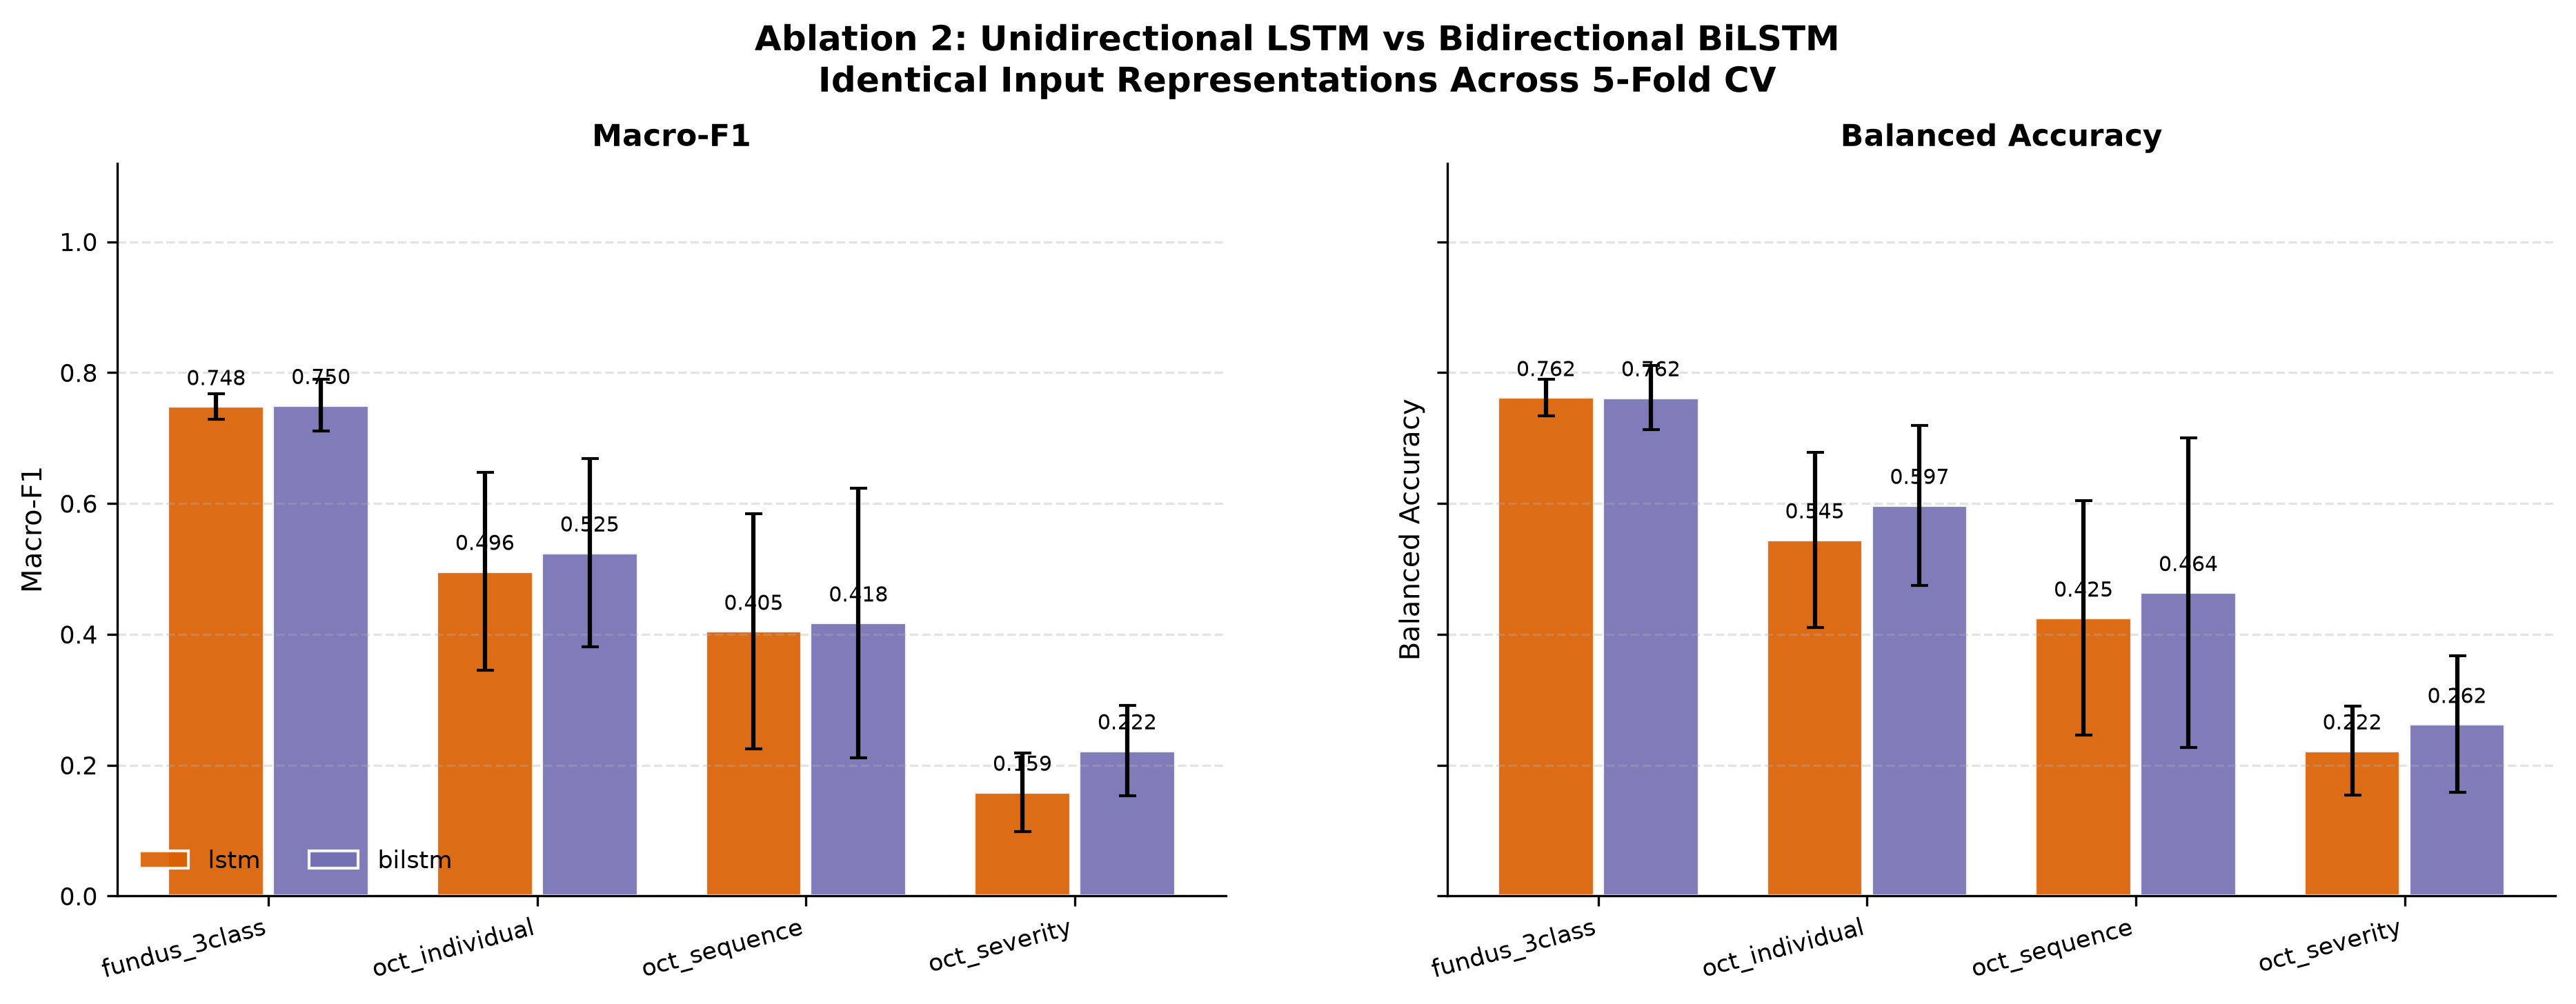

In [3]:
df_abl2 = pd.read_csv(ABL_DIR / "abl02_rnn_lstm_vs_bilstm.csv")
display(HTML("<h4>Ablation 2: LSTM vs BiLSTM Comparison (5-Fold Mean ± SD)</h4>"))
display(HTML(df_abl2[cols_abl].to_html(classes="table table-striped table-hover", index=False)))

display(HTML("<h5>Ablation 2 Figure: LSTM vs BiLSTM Comparison</h5>"))
display(Image(filename=str(FIG_DIR / "abl02_rnn_lstm_vs_bilstm.png")))


## 3. Ablation 3: Hybrid CNN–RNN Architectures vs. Pure CNNs

Analyzing whether recurrent temporal/patch pooling atop convolutional feature extractors outperforms spatial average pooling alone on 2D images.


track,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,accuracy_mean,mcc_mean,total_params,train_time_mean_sec
fundus_3class,resnet50_bilstm,0.962429,0.005684,0.963720,0.969271,0.947654,0,157.75
fundus_3class,efficientnet_b0_bilstm,0.961106,0.019889,0.963990,0.968536,0.946659,0,146.36
fundus_3class,efficientnet_b0,0.959179,0.016450,0.963011,0.965602,0.941763,0,113.84
fundus_3class,resnet50,0.953829,0.014680,0.957292,0.961956,0.935506,0,122.27
fundus_3class,resnet50_lstm,0.953484,0.017039,0.956581,0.961953,0.935692,0,136.11
oct_individual,resnet50_bilstm,0.919313,0.082997,0.940460,0.949438,0.874821,0,111.98
oct_individual,efficientnet_b0_bilstm,0.912103,0.072318,0.933979,0.947397,0.868548,0,91.04
oct_individual,efficientnet_b0,0.905027,0.074724,0.948519,0.934129,0.855422,0,89.65
oct_individual,resnet50,0.889502,0.070958,0.921198,0.926429,0.834327,0,104.14
oct_individual,resnet50_lstm,0.871165,0.077021,0.903005,0.915633,0.808837,0,107.75


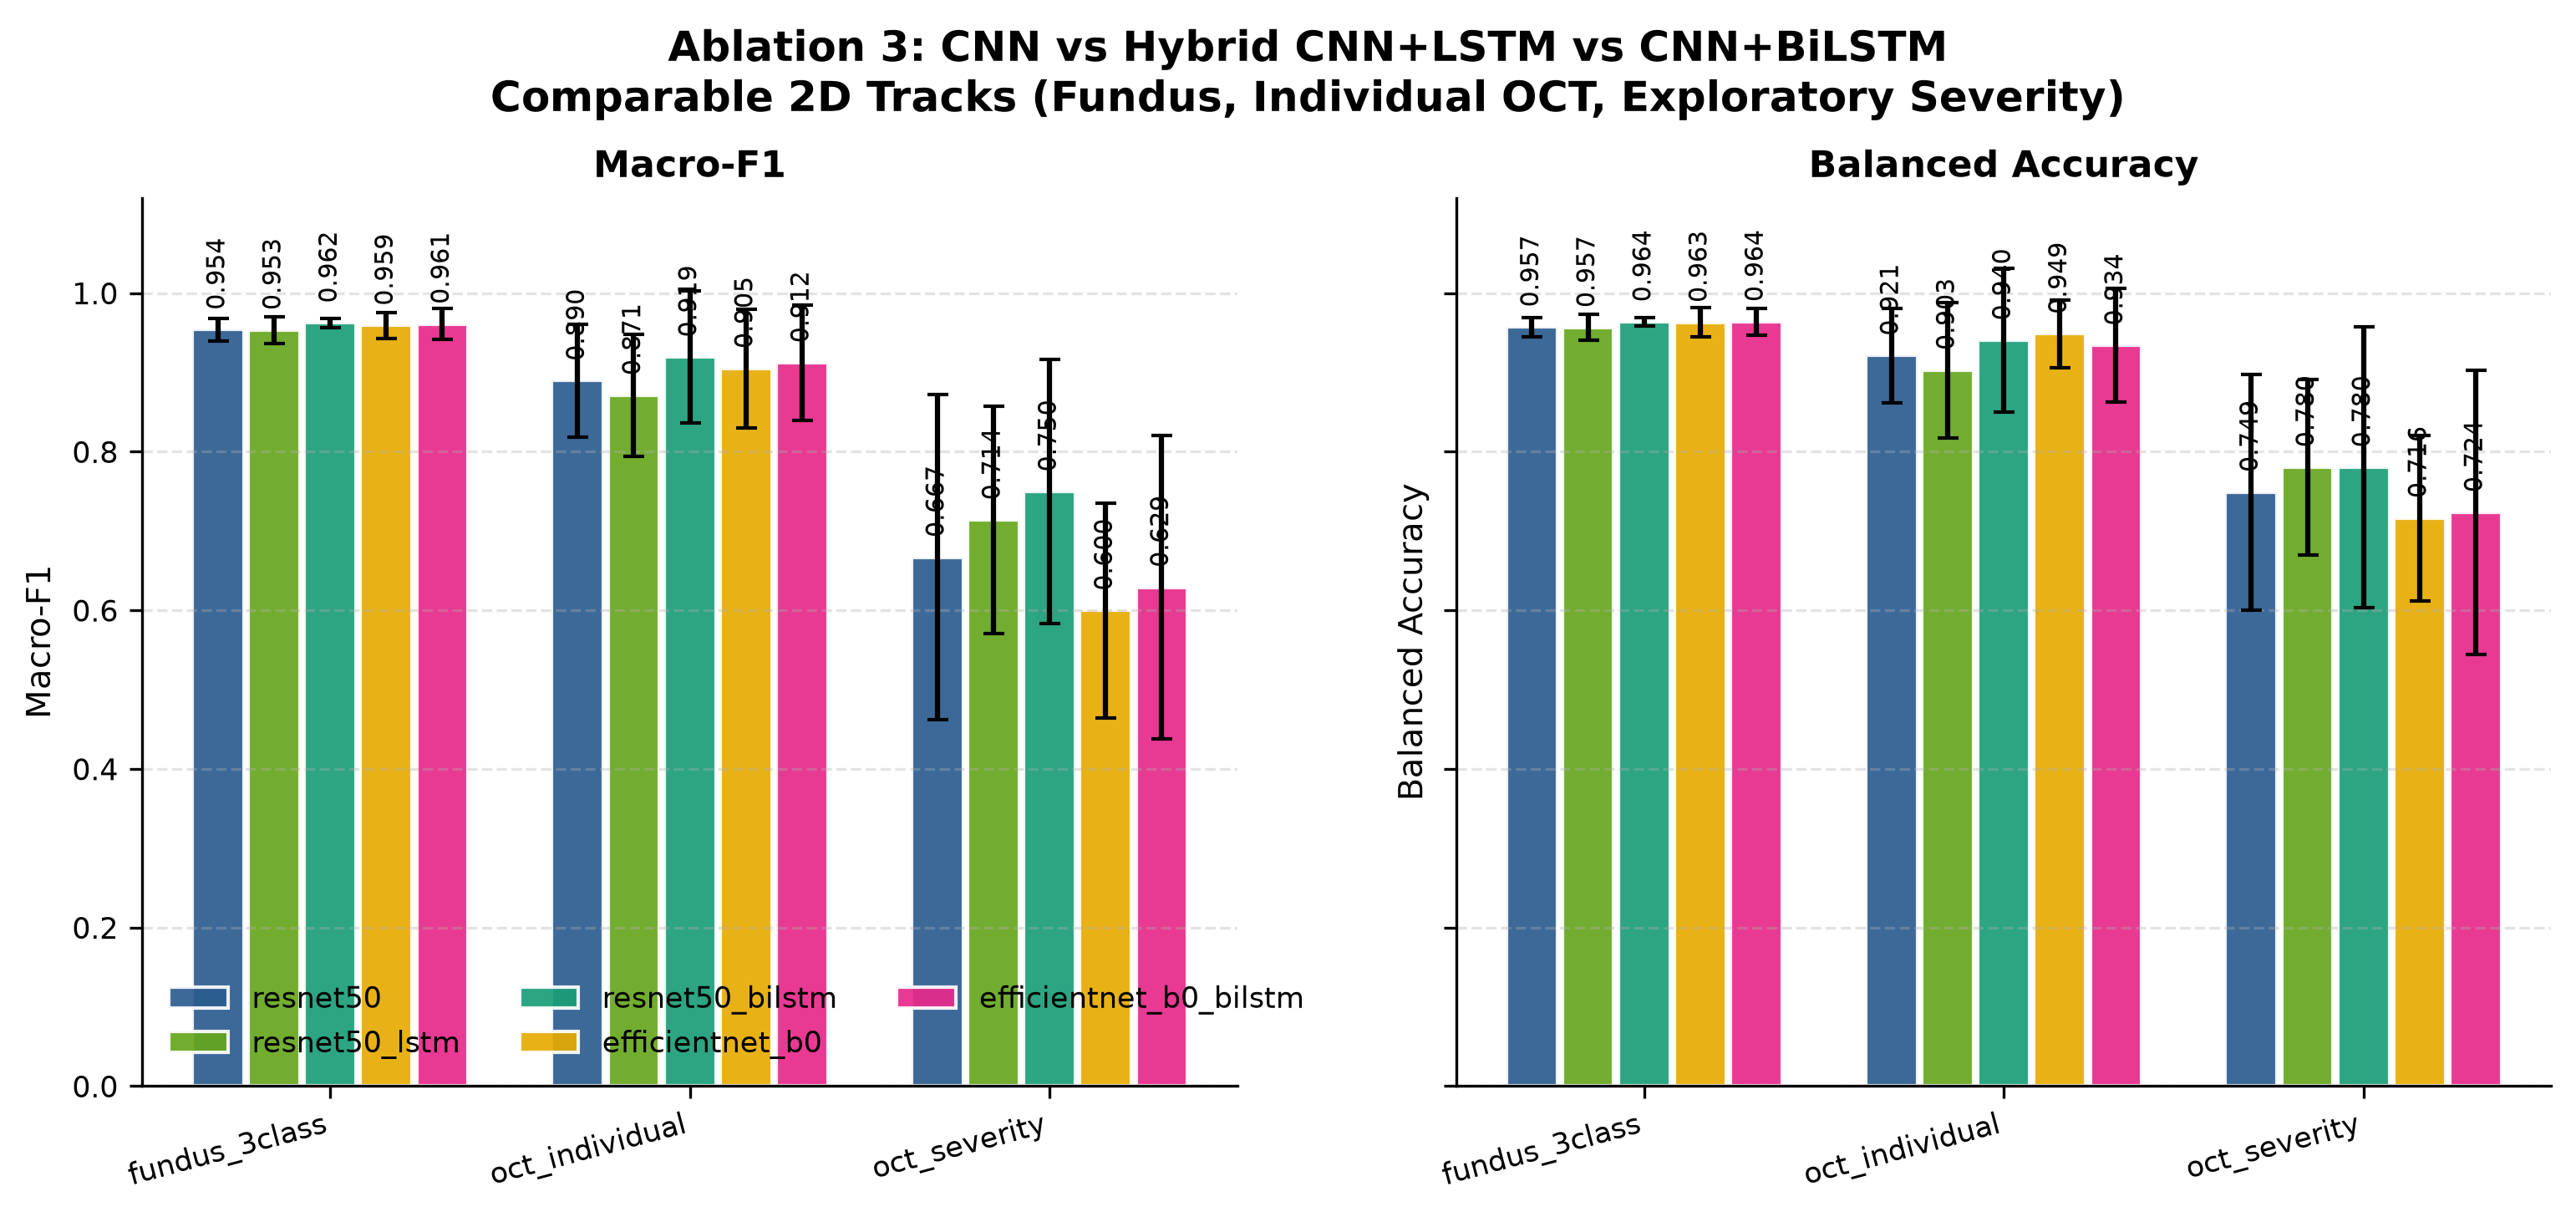

In [4]:
df_abl3 = pd.read_csv(ABL_DIR / "abl03_hybrid_cnn_rnn_comparison.csv")
display(HTML("<h4>Ablation 3: Hybrid vs CNN-Only Architectures (5-Fold Mean ± SD)</h4>"))
display(HTML(df_abl3[cols_abl].to_html(classes="table table-striped table-hover", index=False)))

display(HTML("<h5>Ablation 3 Figure: Hybrid vs CNN Comparison</h5>"))
display(Image(filename=str(FIG_DIR / "abl03_hybrid_cnn_rnn_comparison.png")))


## 4. Ablation 4: Controlled CNN Backbone Trainability (Frozen vs. Partial vs. Full)

Quantifying the exact performance gain achieved by fine-tuning the deep backbone weights compared to linear probing on frozen ImageNet features and partial block tuning.


track,model,backbone_mode,macro_f1_mean,macro_f1_std,bal_acc_mean,acc_mean,trainable_params,total_params,mean_duration_sec,trainable_pct
fundus_3class,efficientnet_b0,frozen,0.959179,0.016450,0.963011,0.965602,4011391,4011391,127.1694,100.0
fundus_3class,efficientnet_b0,full,0.959179,0.016450,0.963011,0.965602,0,0,113.8376,NaN
fundus_3class,efficientnet_b0,partial,0.959179,0.016450,0.963011,0.965602,4011391,4011391,126.0294,100.0
oct_individual,densenet121,frozen,0.962143,0.047931,0.985527,0.976454,6950659,6950659,118.5890,100.0
oct_individual,densenet121,full,0.962143,0.047931,0.985527,0.976454,0,0,135.8074,NaN
oct_individual,densenet121,partial,0.962143,0.047931,0.985527,0.976454,6950659,6950659,118.7858,100.0


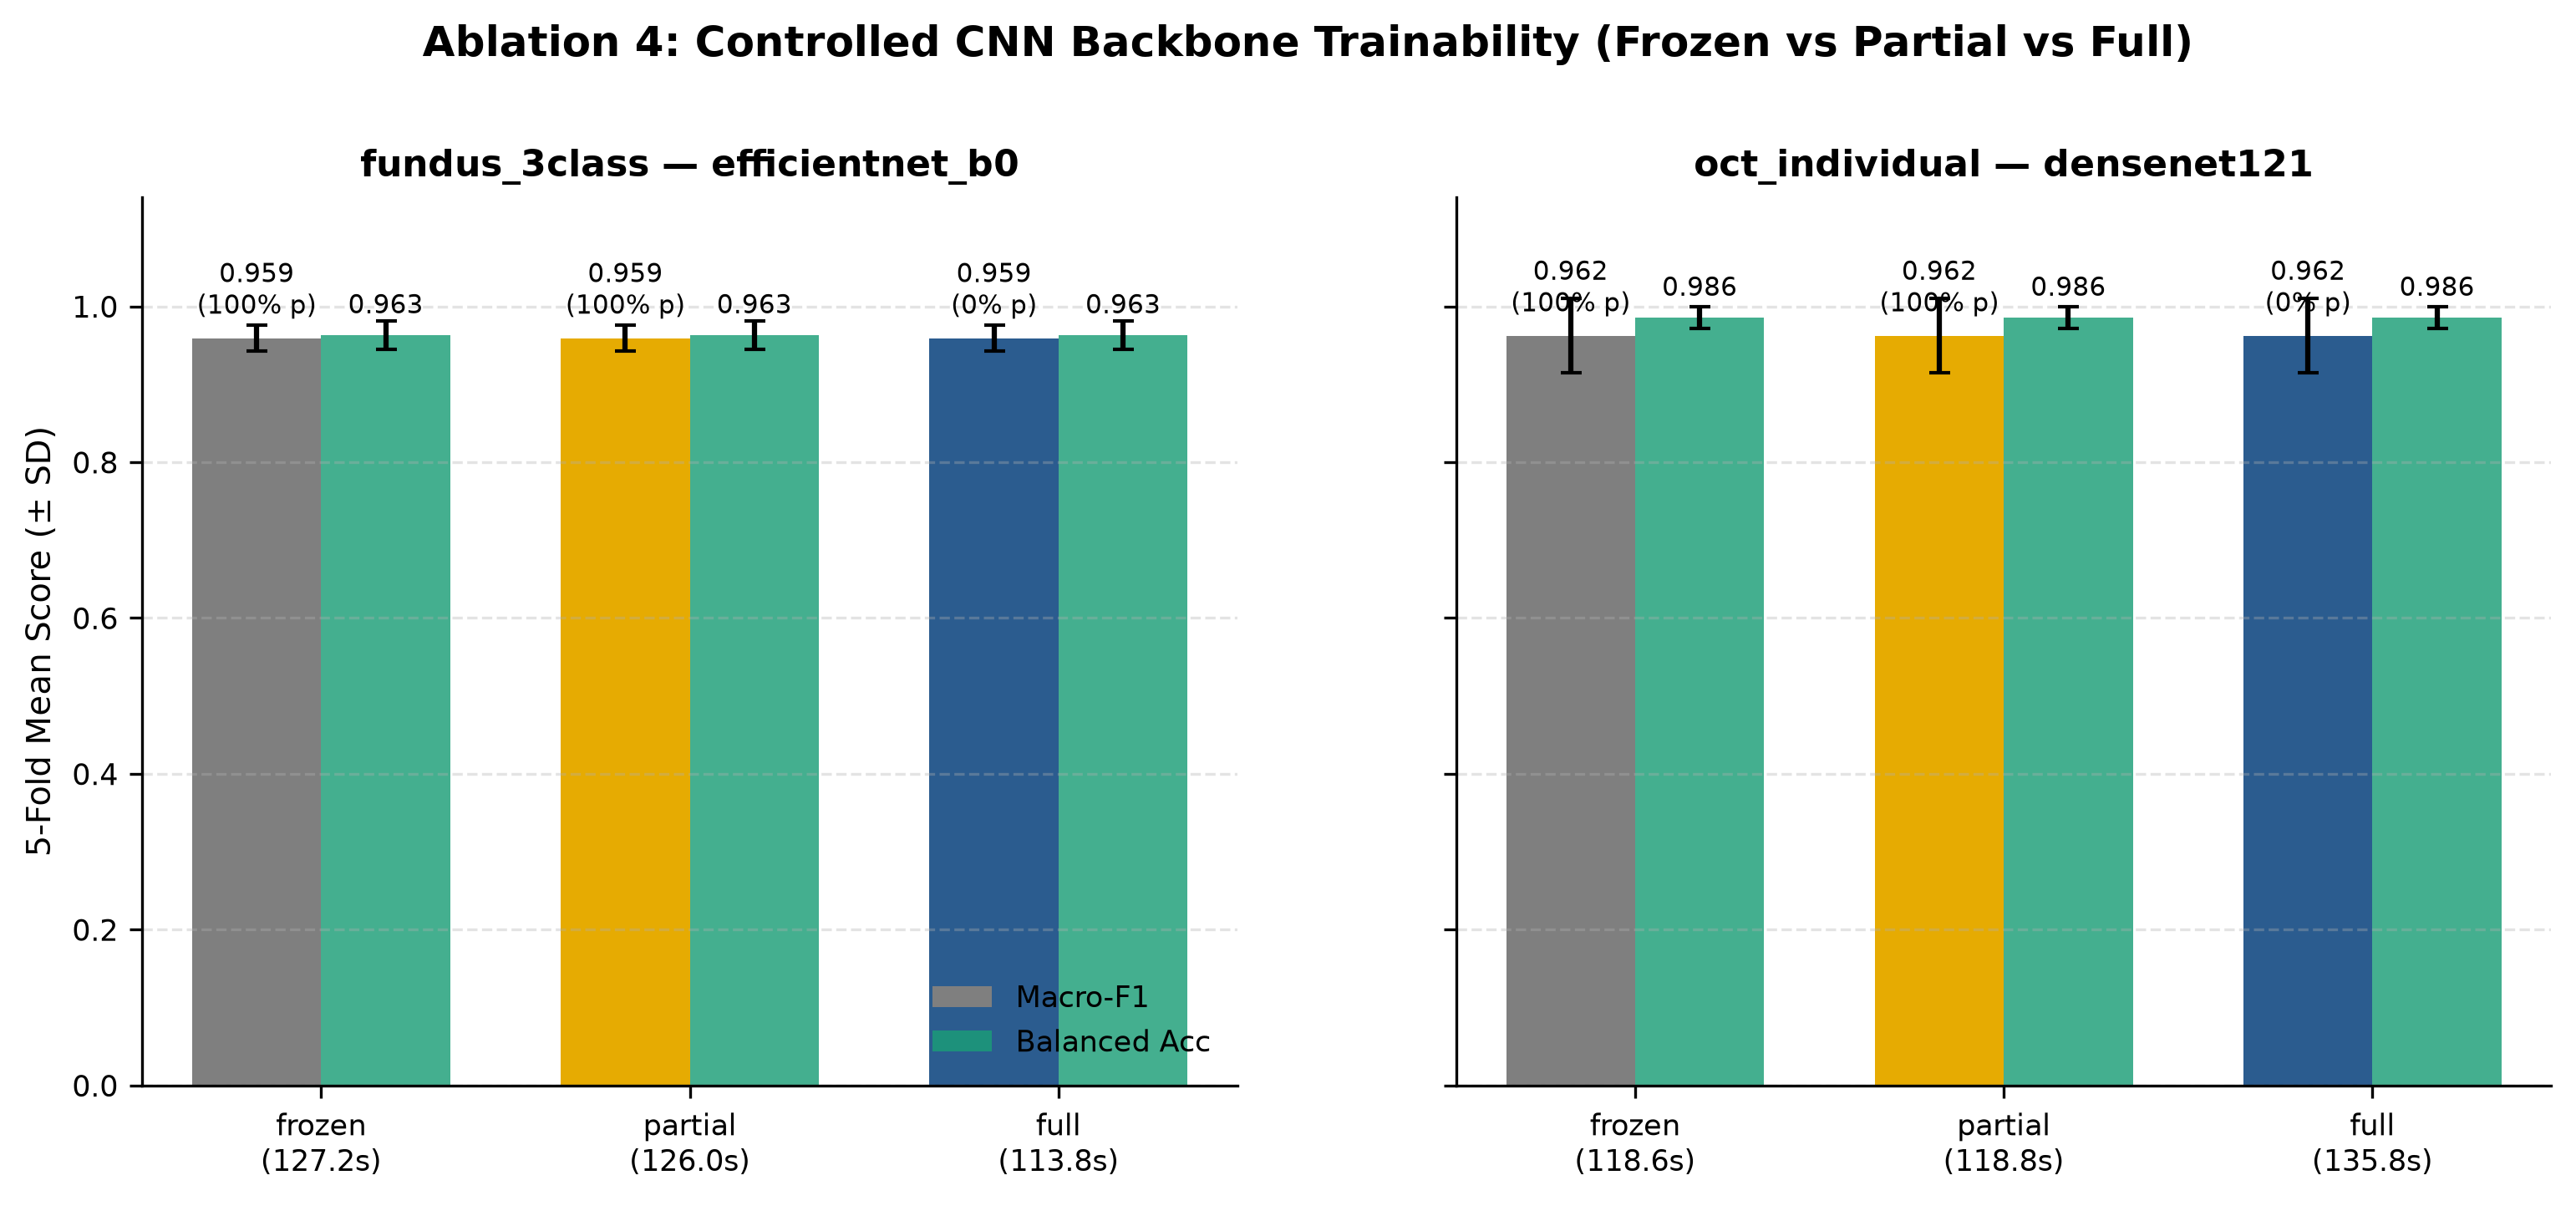

In [5]:
df_abl4 = pd.read_csv(ABL_DIR / "abl04_backbone_trainability_folds.csv")
agg_abl4 = df_abl4.groupby(["track", "model", "backbone_mode"]).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    bal_acc_mean=("balanced_accuracy", "mean"),
    acc_mean=("accuracy", "mean"),
    trainable_params=("trainable_params", "first"),
    total_params=("total_params", "first"),
    mean_duration_sec=("train_duration_sec", "mean")
).reset_index()

agg_abl4["trainable_pct"] = (100.0 * agg_abl4["trainable_params"] / agg_abl4["total_params"]).round(1)
display(HTML("<h4>Ablation 4: Backbone Trainability Summary (5-Fold Mean ± SD)</h4>"))
display(HTML(agg_abl4.to_html(classes="table table-striped table-hover", index=False)))

display(HTML("<h5>Ablation 4 Figure: Backbone Trainability Impact</h5>"))
display(Image(filename=str(FIG_DIR / "abl04_backbone_trainability_comparison.png")))


## 5. Ablation 5: Controlled OCT Sequence Window Length ($L=4$ vs $L=8$ vs $L=12$)

Evaluating how the volumetric temporal window span affects both window-level and patient sequence-level classification performance with ResNet50+BiLSTM.


seq_len,n_windows_oof,macro_f1_mean,macro_f1_std,acc_mean,mcc_mean,mean_duration_sec
4,285,0.881972,0.098682,0.925602,0.832183,84.8900
8,146,0.898361,0.084457,0.919144,0.842974,93.7440
12,99,0.890320,0.080527,0.927264,0.830294,91.5238


seq_len,n_sequences,seq_accuracy,seq_macro_f1,seq_mcc
4,21,0.952381,0.923232,0.876867
8,21,0.904762,0.868056,0.785714
12,21,0.952381,0.923232,0.876867


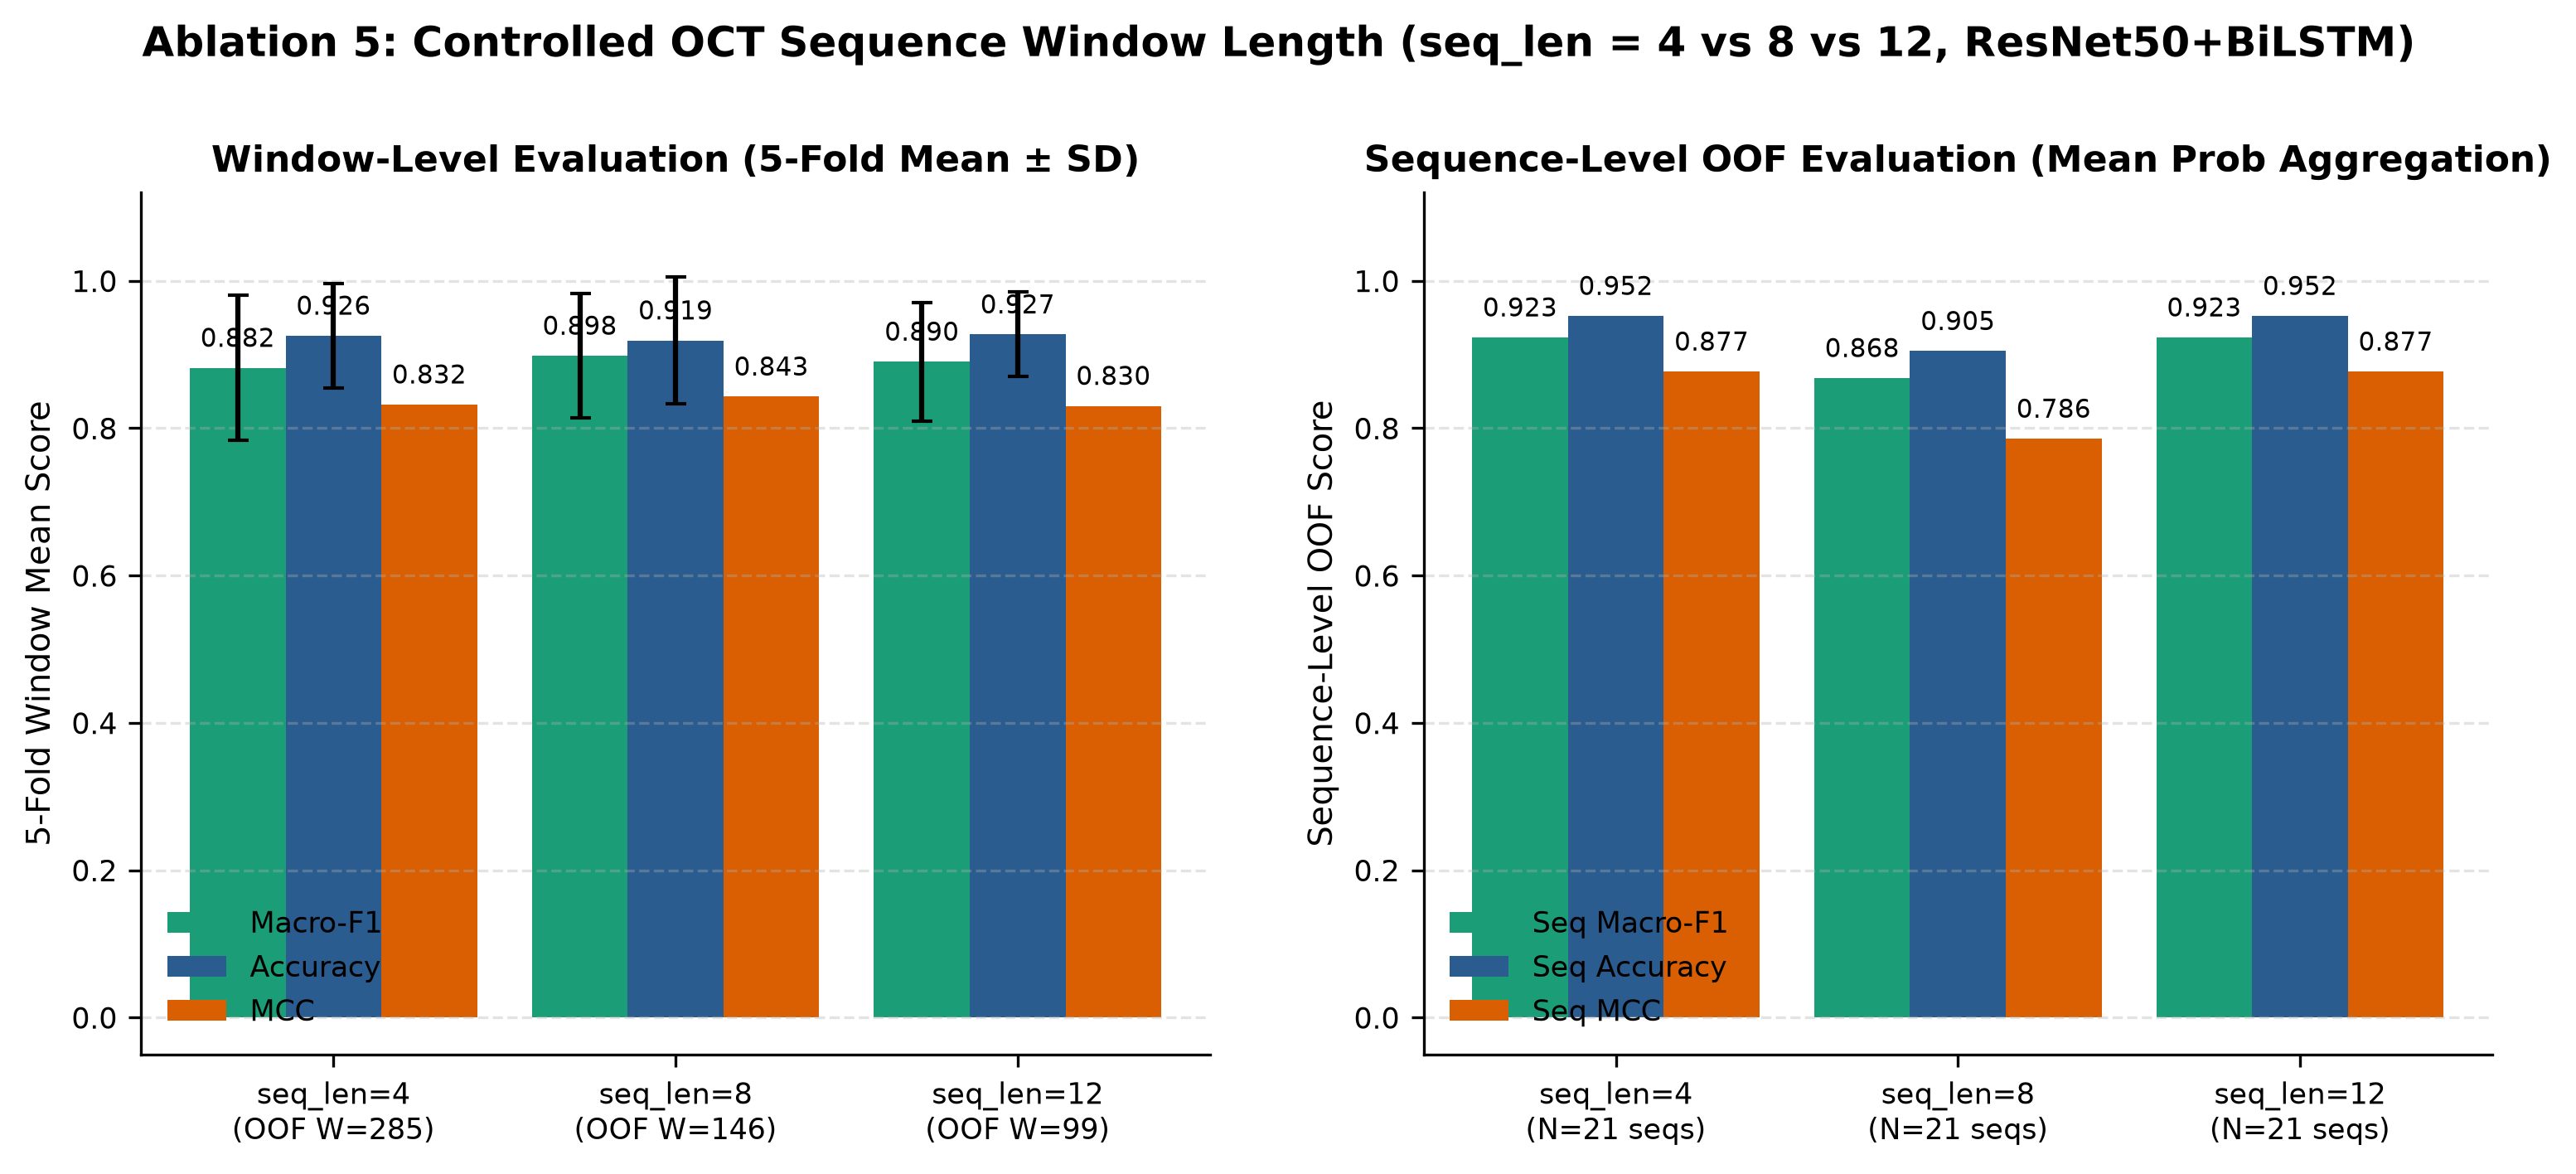

In [6]:
df_abl5_folds = pd.read_csv(ABL_DIR / "abl05_oct_sequence_length_folds.csv")
agg_abl5 = df_abl5_folds.groupby("seq_len").agg(
    n_windows_oof=("n_windows", "sum"),
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    acc_mean=("accuracy", "mean"),
    mcc_mean=("mcc", "mean"),
    mean_duration_sec=("train_duration_sec", "mean")
).reset_index()

display(HTML("<h4>Ablation 5: Window-Level Performance by Sequence Length (5-Fold Mean ± SD)</h4>"))
display(HTML(agg_abl5.to_html(classes="table table-striped table-hover", index=False)))

df_abl5_lvl = pd.read_csv(ABL_DIR / "abl05_oct_sequence_length_seq_level.csv")
display(HTML("<h4>Ablation 5: Patient Sequence-Level Out-of-Fold Performance (N=21 Sequences)</h4>"))
display(HTML(df_abl5_lvl.to_html(classes="table table-striped table-hover", index=False)))

display(HTML("<h5>Ablation 5 Figure: Window & Sequence-Level Length Comparison</h5>"))
display(Image(filename=str(FIG_DIR / "abl05_oct_sequence_length_comparison.png")))


## 6. Synthesis: Parameter Complexity vs Training Duration vs Performance

Tradeoff scatter visualization illustrating the efficiency frontiers across architecture paradigms and modalities.


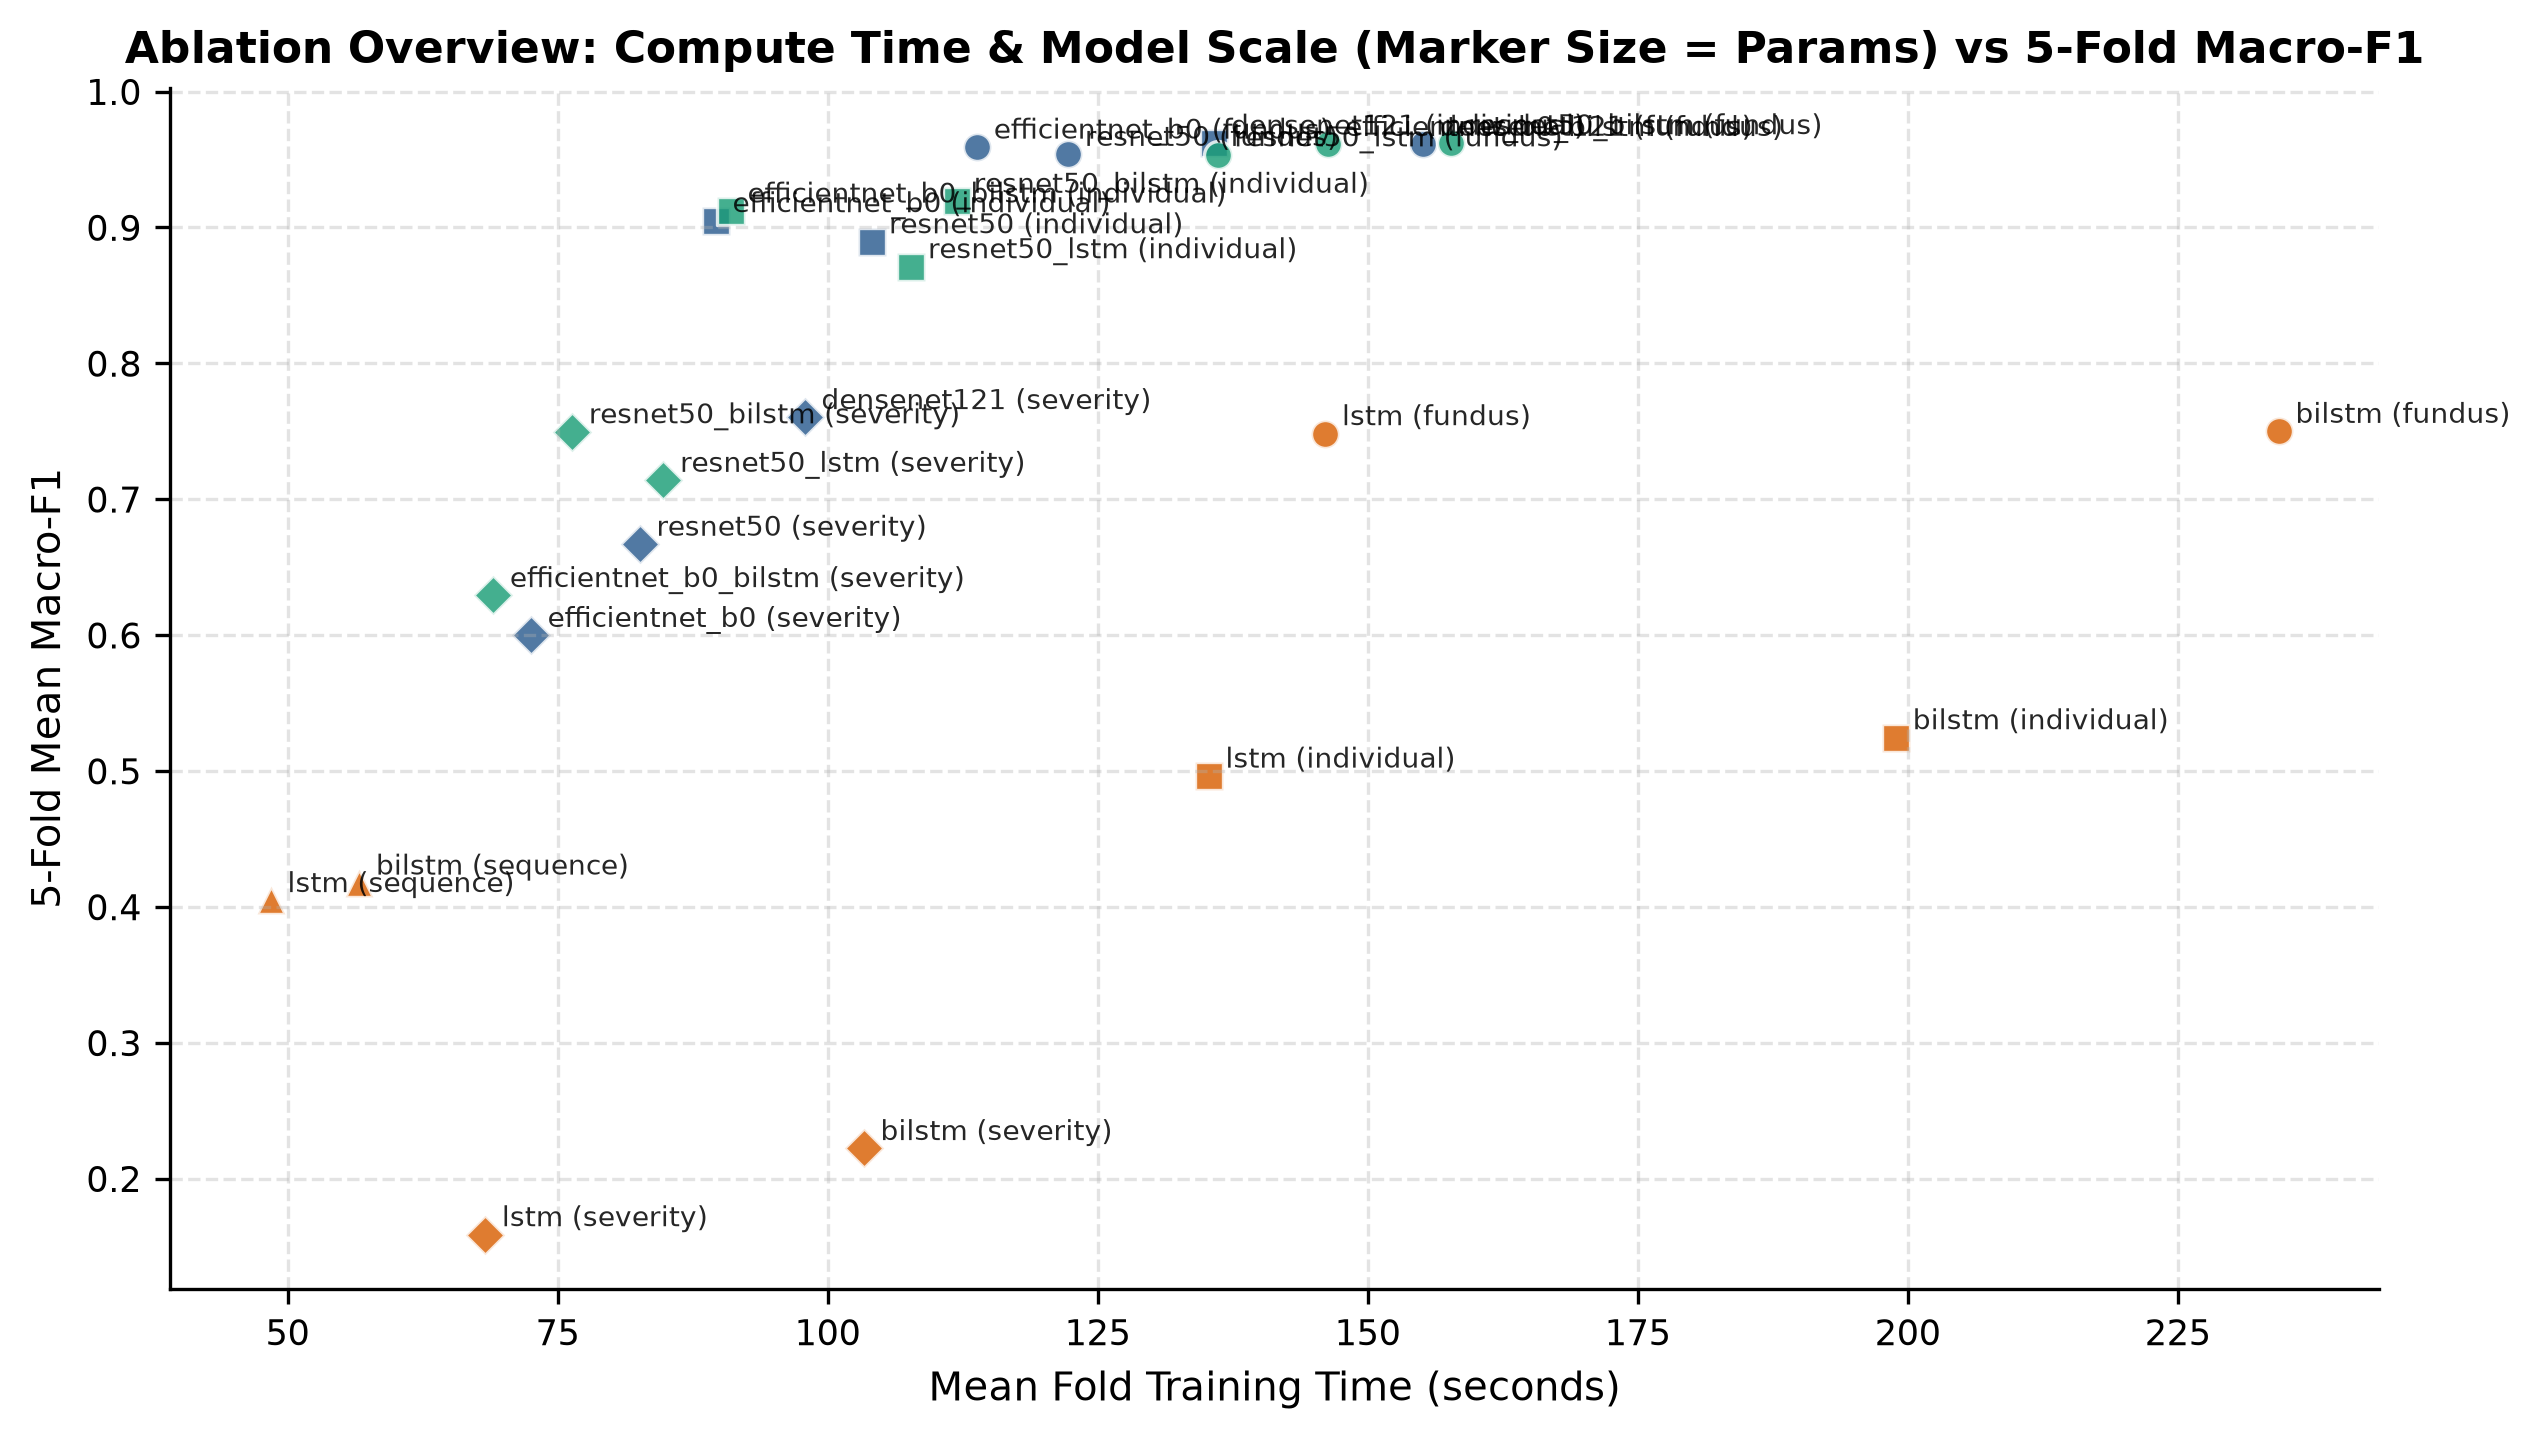

In [7]:
display(HTML("<h5>Ablation 6: Efficiency & Compute Tradeoff Overview</h5>"))
display(Image(filename=str(FIG_DIR / "abl06_ablation_efficiency_tradeoff.png")))
